# MScFE 660 — Risk Management | Group Work Project 2
## Hidden Markov Models & Bayesian Network for Oil Price Regime Detection

| Field | Details |
|---|---|
| **Course** | MScFE 660 Risk Management |
| **Methodology** | 3-state Gaussian HMM (`hmmlearn`) + Bayesian Network (`pgmpy` Hill Climb) |
| **Data Sources** | FRED, Yahoo Finance (real data, 2005–2024) |

---

### ▶ Quick-Start (Google Colab)
1. **Runtime → Secrets** → add key `FRED_API_KEY`  
   (Free key at <https://fred.stlouisfed.org/docs/api/api_key.html>)  
2. **Runtime → Run all**



## Install Dependencies


In [1]:
# Install all required packages (quiet mode suppresses verbose output)
%pip install fredapi yfinance hmmlearn pgmpy statsmodels \
             pandas numpy matplotlib seaborn scipy scikit-learn --quiet
print("✓ All packages installed.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 6.9 MB/s eta 0:00:00
✓ All packages installed.


## Imports & Configuration

In [2]:
# ── Standard library ──────────────────────────────────────────────────────────
import os
import warnings
import math
import itertools

# ── Numerical / data ──────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy import stats
from scipy.special import logsumexp
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.stattools import adfuller

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
import seaborn as sns

# ── HMM ───────────────────────────────────────────────────────────────────────
from hmmlearn.hmm import GaussianHMM

# ── Bayesian Network (supports both pgmpy < 0.1.23 and >= 0.1.23) ────────────
from pgmpy.models import BayesianNetwork, DiscreteBayesianNetwork
#-from pgmpy.estimators import HillClimbSearch, MaximumLikelihoodEstimator
from pgmpy.estimators import HillClimbSearch
from pgmpy.parameter_estimator import DiscreteMLE
from pgmpy.inference import VariableElimination

# BicScore import — path changed in pgmpy 0.1.23
try:
    from pgmpy.structure_score import BIC as BicScore
    print("pgmpy ≥ 0.1.23: BicScore from pgmpy.structure_score")
except ImportError:
    try:
        from pgmpy.estimators import BicScore
        print("pgmpy < 0.1.23: BicScore from pgmpy.estimators")
    except ImportError:
        from pgmpy.estimators import K2Score as BicScore
        print("Fallback: using K2Score")

# ── External data ─────────────────────────────────────────────────────────────
import yfinance as yf
from fredapi import Fred

# ── Global settings ───────────────────────────────────────────────────────────
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

# ── Output directories ────────────────────────────────────────────────────────
PLOTS_DIR = "/content/plots"
DATA_DIR  = "/content/data"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR,  exist_ok=True)

# ── Study period ──────────────────────────────────────────────────────────────
START, END = "2005-01-01", "2024-12-31"

# ── FRED API key (add to Colab Secrets as FRED_API_KEY) ───────────────────────
try:
    from google.colab import userdata
    FRED_API_KEY = userdata.get("FRED_API_KEY")
except Exception:
    FRED_API_KEY = "1fdadf233df690f8e67d7378ad022703"  # fallback key

fred = Fred(api_key=FRED_API_KEY)

print(f"✓ Setup complete  |  Study period: {START} → {END}")
print(f"  Plots → {PLOTS_DIR}  |  Data → {DATA_DIR}")


/usr/local/lib/python3.12/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


pgmpy ≥ 0.1.23: BicScore from pgmpy.structure_score
✓ Setup complete  |  Study period: 2005-01-01 → 2024-12-31
  Plots → /content/plots  |  Data → /content/data


## Data Loading (WTI + Macro, 2005–2024)

In [3]:
# ── Helper: resample any FRED series to month-start ───────────────────────────
def to_monthly(series: pd.Series) -> pd.Series:
    """Resample a FRED series to month-start frequency, forward-fill gaps."""
    series.index = pd.to_datetime(series.index)
    return series.resample("MS").last().ffill()


# ── Load WTI spot price ───────────────────────────────────────────────────────
print("Loading WTI spot price (WTISPLC) from FRED ...")
wti = to_monthly(
    fred.get_series("WTISPLC", observation_start=START, observation_end=END)
).dropna()
print(f"  WTI: {len(wti)} obs  [{wti.index[0].date()} → {wti.index[-1].date()}]")


# ── Load macro variables ──────────────────────────────────────────────────────
print("Loading macro variables from FRED ...")
indpro  = to_monthly(fred.get_series("INDPRO",   observation_start=START, observation_end=END))
cpi_nrg = to_monthly(fred.get_series("CPIENGSL", observation_start=START, observation_end=END))
dxy     = to_monthly(fred.get_series("DTWEXBGS", observation_start=START, observation_end=END))


# ── Load VIX from Yahoo Finance ───────────────────────────────────────────────
print("Loading VIX (^VIX) from Yahoo Finance ...")
vix_raw = yf.download("^VIX", start=START, end=END,
                       interval="1mo", progress=False, auto_adjust=True)
vix = (vix_raw["Close"]
       .squeeze()
       .pipe(lambda s: s.set_axis(pd.to_datetime(s.index).to_period("M").to_timestamp())))


# ── Assemble master DataFrame ─────────────────────────────────────────────────
df_raw = pd.DataFrame(
    {"WTI": wti, "IndPro": indpro, "CPI_Nrg": cpi_nrg, "DXY": dxy, "VIX": vix}
).dropna()

print(f"\nMaster DataFrame: {df_raw.shape}  "
      f"[{df_raw.index[0].date()} → {df_raw.index[-1].date()}]")


# ── Derive return / volatility features ──────────────────────────────────────
df = df_raw.copy()
df["WTI_ret"]    = np.log(df["WTI"]    / df["WTI"].shift(1))
df["WTI_vol12"]  = df["WTI_ret"].rolling(12).std() * np.sqrt(12)   # annualised
df["IndPro_ret"] = np.log(df["IndPro"] / df["IndPro"].shift(1))
df["DXY_ret"]    = np.log(df["DXY"]    / df["DXY"].shift(1))
df.dropna(inplace=True)

print(f"With derived features: {df.shape}")
df[["WTI", "WTI_ret", "WTI_vol12", "VIX"]].describe().round(3)


Loading WTI spot price (WTISPLC) from FRED ...
  WTI: 240 obs  [2005-01-01 → 2024-12-01]
Loading macro variables from FRED ...
Loading VIX (^VIX) from Yahoo Finance ...

Master DataFrame: (228, 5)  [2006-01-01 → 2024-12-01]
With derived features: (216, 9)


,WTI,WTI_ret,WTI_vol12,VIX
count,216.000,216.000,216.000,216.000
mean,73.019,0.001,0.323,20.028
std,22.108,0.110,0.205,8.372
min,16.550,-0.568,0.134,9.510
25%,54.772,-0.050,0.209,14.022
50%,72.885,0.014,0.251,17.745
75%,89.572,0.057,0.351,23.525
max,133.930,0.546,1.077,59.890


##Step 1A — Forward & Backward Algorithms

In [4]:
# ─────────────────────────────────────────────────────────────────────────────
# THEORY SUMMARY
# ─────────────────────────────────────────────────────────────────────────────
# Forward (α-pass):  α_t(i) = P(o₁..oₜ, qₜ=i | λ)
#   Init:  α₁(i) = π[i] · B[i][o₁]
#   Induct: α_t(j) = B[j][oₜ] · Σᵢ α_{t-1}(i) · A[i][j]
#   Term:   P(O|λ) = Σᵢ α_T(i)
#
# Backward (β-pass): β_t(i) = P(o_{t+1}..oT | qₜ=i, λ)
#   Init:  β_T(i) = 1
#   Induct: β_t(i) = Σⱼ A[i][j] · B[j][o_{t+1}] · β_{t+1}(j)
#   Term:   P(O|λ) = Σᵢ π[i] · B[i][o₁] · β₁(i)
#
# Both run in O(N² T).  We use log-space arithmetic to avoid underflow.
# ─────────────────────────────────────────────────────────────────────────────

# ── Toy HMM: 3-state weather model ───────────────────────────────────────────
#  States:       0=Sunny  1=Cloudy  2=Rainy
#  Observations: 0=Dry    1=Damp    2=Wet

A_toy  = np.array([[0.7, 0.2, 0.1],
                   [0.3, 0.4, 0.3],
                   [0.2, 0.3, 0.5]])   # transition matrix

B_toy  = np.array([[0.6, 0.3, 0.1],
                   [0.2, 0.5, 0.3],
                   [0.1, 0.2, 0.7]])   # emission matrix

pi_toy = np.array([0.5, 0.3, 0.2])    # initial state distribution
O_toy  = [0, 1, 2]                    # observed sequence: Dry → Damp → Wet

STATE_NAMES = ["Sunny", "Cloudy", "Rainy"]
OBS_NAMES   = ["Dry",   "Damp",   "Wet"]

N, T = len(pi_toy), len(O_toy)


def forward_log(pi, A, B, O):
    """Log-space forward pass. Returns log_alpha (T×N) and log P(O|λ)."""
    T_len, N_states = len(O), len(pi)
    log_a = np.full((T_len, N_states), -np.inf)
    log_a[0] = np.log(pi) + np.log(B[:, O[0]])
    for t in range(1, T_len):
        for j in range(N_states):
            log_a[t, j] = np.log(B[j, O[t]]) + logsumexp(log_a[t-1] + np.log(A[:, j]))
    return log_a, float(logsumexp(log_a[-1]))


def backward_log(pi, A, B, O):
    """Log-space backward pass. Returns log_beta (T×N) and log P(O|λ)."""
    T_len, N_states = len(O), len(pi)
    log_b = np.full((T_len, N_states), -np.inf)
    log_b[-1] = 0.0                    # β_T = 1 → log(1) = 0
    for t in range(T_len - 2, -1, -1):
        for i in range(N_states):
            log_b[t, i] = logsumexp(
                np.log(A[i]) + np.log(B[:, O[t+1]]) + log_b[t+1]
            )
    log_p = float(logsumexp(np.log(pi) + np.log(B[:, O[0]]) + log_b[0]))
    return log_b, log_p


# ── Run ───────────────────────────────────────────────────────────────────────
log_alpha, log_p_fwd = forward_log(pi_toy, A_toy, B_toy, O_toy)
log_beta,  log_p_bwd = backward_log(pi_toy, A_toy, B_toy, O_toy)

alpha = np.exp(log_alpha)
beta  = np.exp(log_beta)

print("Forward Algorithm — Toy Example")
print(f"  Observation sequence: {[OBS_NAMES[o] for o in O_toy]}")
for t in range(T):
    row = "  ".join(f"α({STATE_NAMES[i]})={alpha[t,i]:.6f}" for i in range(N))
    print(f"  t={t+1}: {row}")
print(f"  P(O|λ) via Forward  = {np.exp(log_p_fwd):.8f}")

print("\nBackward Algorithm — Toy Example")
for t in range(T):
    row = "  ".join(f"β({STATE_NAMES[i]})={beta[t,i]:.6f}" for i in range(N))
    print(f"  t={t+1}: {row}")
print(f"  P(O|λ) via Backward = {np.exp(log_p_bwd):.8f}")
print(f"\n  ✓ Both algorithms yield P(O|λ) ≈ {np.exp(log_p_fwd):.8f}")


Forward Algorithm — Toy Example
  Observation sequence: ['Dry', 'Damp', 'Wet']
  t=1: α(Sunny)=0.300000  α(Cloudy)=0.060000  α(Rainy)=0.020000
  t=2: α(Sunny)=0.069600  α(Cloudy)=0.045000  α(Rainy)=0.011600
  t=3: α(Sunny)=0.006454  α(Cloudy)=0.010620  α(Rainy)=0.018382
  P(O|λ) via Forward  = 0.03545600

Backward Algorithm — Toy Example
  t=1: β(Sunny)=0.087200  β(Cloudy)=0.117600  β(Rainy)=0.112000
  t=2: β(Sunny)=0.200000  β(Cloudy)=0.360000  β(Rainy)=0.460000
  t=3: β(Sunny)=1.000000  β(Cloudy)=1.000000  β(Rainy)=1.000000
  P(O|λ) via Backward = 0.03545600

  ✓ Both algorithms yield P(O|λ) ≈ 0.03545600


##Step 1B — Viterbi Algorithm

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# THEORY SUMMARY
# ─────────────────────────────────────────────────────────────────────────────
# Finds the single most likely hidden-state path Q* = argmax_Q P(Q,O|λ).
#
# δ_t(i) = max_{q₁..q_{t-1}} P(q₁..q_{t-1}, qₜ=i, o₁..oₜ | λ)
# ψ_t(j) = argmax_i [ δ_{t-1}(i) · A[i][j] ]   (backpointer)
#
# Init:    δ₁(i) = π[i] · B[i][o₁]
# Induct:  δ_t(j) = B[j][oₜ] · max_i[δ_{t-1}(i) · A[i][j]]
# Backtrace from q*_T = argmax δ_T.
# Complexity O(N² T).  Log-space used throughout.
# ─────────────────────────────────────────────────────────────────────────────

def viterbi_log(pi, A, B, O):
    """Log-space Viterbi. Returns (best_path, log_prob)."""
    T_len, N_states = len(O), len(pi)
    log_d = np.full((T_len, N_states), -np.inf)
    psi   = np.zeros((T_len, N_states), dtype=int)

    log_d[0] = np.log(pi) + np.log(B[:, O[0]])
    for t in range(1, T_len):
        for j in range(N_states):
            scores     = log_d[t-1] + np.log(A[:, j])
            psi[t, j]  = int(np.argmax(scores))
            log_d[t, j] = scores[psi[t, j]] + np.log(B[j, O[t]])

    path = np.zeros(T_len, dtype=int)
    path[-1] = int(np.argmax(log_d[-1]))
    for t in range(T_len - 2, -1, -1):
        path[t] = psi[t+1, path[t+1]]

    return path, float(log_d[-1, path[-1]])


# ── Run ───────────────────────────────────────────────────────────────────────
best_path, log_prob_viterbi = viterbi_log(pi_toy, A_toy, B_toy, O_toy)

print("Viterbi Algorithm — Toy Example")
print(f"  Observation sequence  : {[OBS_NAMES[o] for o in O_toy]}")
print(f"  Most likely states Q* : {[STATE_NAMES[s] for s in best_path]}")
print(f"  log P(Q*,O|λ)         : {log_prob_viterbi:.6f}")
print(f"  P(Q*,O|λ)             : {np.exp(log_prob_viterbi):.8f}")

print("\n  Delta matrix (log-probabilities):")
log_delta_toy = np.full((T, N), -np.inf)
log_delta_toy[0] = np.log(pi_toy) + np.log(B_toy[:, O_toy[0]])
for t in range(1, T):
    for j in range(N):
        scores = log_delta_toy[t-1] + np.log(A_toy[:, j])
        log_delta_toy[t, j] = max(scores) + np.log(B_toy[j, O_toy[t]])
for t in range(T):
    row = "  ".join(f"δ({STATE_NAMES[i]})={log_delta_toy[t,i]:.4f}" for i in range(N))
    print(f"  t={t+1}: {row}")

print(f"\n  Interpretation: Given (Dry→Damp→Wet) the most likely sequence was "
      f"{' → '.join(STATE_NAMES[s] for s in best_path)}")


Viterbi Algorithm — Toy Example
  Observation sequence  : ['Dry', 'Damp', 'Wet']
  Most likely states Q* : ['Sunny', 'Cloudy', 'Rainy']
  log P(Q*,O|λ)         : -5.067206
  P(Q*,O|λ)             : 0.00630000

  Delta matrix (log-probabilities):
  t=1: δ(Sunny)=-1.2040  δ(Cloudy)=-2.8134  δ(Rainy)=-3.9120
  t=2: δ(Sunny)=-2.7646  δ(Cloudy)=-3.5066  δ(Rainy)=-5.1160
  t=3: δ(Sunny)=-5.4239  δ(Cloudy)=-5.5780  δ(Rainy)=-5.0672

  Interpretation: Given (Dry→Damp→Wet) the most likely sequence was Sunny → Cloudy → Rainy


##Step 1C — Baum-Welch Algorithm

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# THEORY SUMMARY
# ─────────────────────────────────────────────────────────────────────────────
# EM algorithm for HMM parameter learning: find λ=(A,B,π) maximising P(O|λ).
#
# E-step — compute responsibilities using α and β:
#   γ_t(i)   = P(qₜ=i | O,λ) = α_t(i)·β_t(i) / P(O|λ)
#   ξ_t(i,j) = P(qₜ=i, q_{t+1}=j | O,λ)
#             = α_t(i)·A[i][j]·B[j][o_{t+1}]·β_{t+1}(j) / P(O|λ)
#
# M-step — re-estimate parameters:
#   π̂[i]   = γ_1(i)
#   Â[i][j] = Σ_t ξ_t(i,j) / Σ_t γ_t(i)
#   B̂[i][k] = Σ_{t:oₜ=k} γ_t(i) / Σ_t γ_t(i)
#
# Guaranteed convergence to a local maximum. hmmlearn runs many iterations.
# ─────────────────────────────────────────────────────────────────────────────

# ── One E/M round on the toy HMM (reuses α and β from Cell 4) ────────────────
log_p_fwd_toy = float(logsumexp(log_alpha[-1]))

# γ: state responsibilities
log_gamma = log_alpha + log_beta - log_p_fwd_toy
gamma     = np.exp(log_gamma)

# ξ: joint transition responsibilities
xi = np.zeros((T - 1, N, N))
for t in range(T - 1):
    for i in range(N):
        for j in range(N):
            xi[t, i, j] = np.exp(
                log_alpha[t, i]
                + np.log(A_toy[i, j])
                + np.log(B_toy[j, O_toy[t+1]])
                + log_beta[t+1, j]
                - log_p_fwd_toy
            )

# M-step re-estimates
pi_new = gamma[0]
A_new  = xi.sum(axis=0) / gamma[:-1].sum(axis=0, keepdims=True).T
B_new  = np.zeros_like(B_toy)
for k in range(len(OBS_NAMES)):
    mask = np.array(O_toy) == k
    B_new[:, k] = gamma[mask].sum(axis=0) / gamma.sum(axis=0)

# ── Report ────────────────────────────────────────────────────────────────────
print("Baum-Welch — One E/M Iteration on Toy Example")
print("\n  γ (state responsibilities):")
for t in range(T):
    row = "  ".join(f"γ({STATE_NAMES[i]})={gamma[t,i]:.4f}" for i in range(N))
    print(f"  t={t+1}: {row}")

print(f"\n  Updated π̂  : {dict(zip(STATE_NAMES, pi_new.round(4)))}")
print("\n  Updated Â (old → new):")
for i in range(N):
    print(f"  {STATE_NAMES[i]}: {A_toy[i].round(3)} → {A_new[i].round(3)}")
print("\n  Updated B̂ (old → new):")
for i in range(N):
    print(f"  {STATE_NAMES[i]}: {B_toy[i].round(3)} → {B_new[i].round(3)}")
print("\n  In practice hmmlearn iterates until log-likelihood converges.")


Baum-Welch — One E/M Iteration on Toy Example

  γ (state responsibilities):
  t=1: γ(Sunny)=0.7378  γ(Cloudy)=0.1990  γ(Rainy)=0.0632
  t=2: γ(Sunny)=0.3926  γ(Cloudy)=0.4569  γ(Rainy)=0.1505
  t=3: γ(Sunny)=0.1820  γ(Cloudy)=0.2995  γ(Rainy)=0.5184

  Updated π̂  : {'Sunny': np.float64(0.7378), 'Cloudy': np.float64(0.199), 'Rainy': np.float64(0.0632)}

  Updated Â (old → new):
  Sunny: [0.7 0.2 0.1] → [0.436 0.374 0.19 ]
  Cloudy: [0.3 0.4 0.3] → [0.104 0.418 0.478]
  Rainy: [0.2 0.3 0.5] → [0.062 0.28  0.657]

  Updated B̂ (old → new):
  Sunny: [0.6 0.3 0.1] → [0.562 0.299 0.139]
  Cloudy: [0.2 0.5 0.3] → [0.208 0.478 0.313]
  Rainy: [0.1 0.2 0.7] → [0.086 0.206 0.708]

  In practice hmmlearn iterates until log-likelihood converges.


##Step 2 — Bull, Bear & Stagnant Regime Identification

Rule-Based Regime Counts:
Stagnant    87
Bull        79
Bear        50


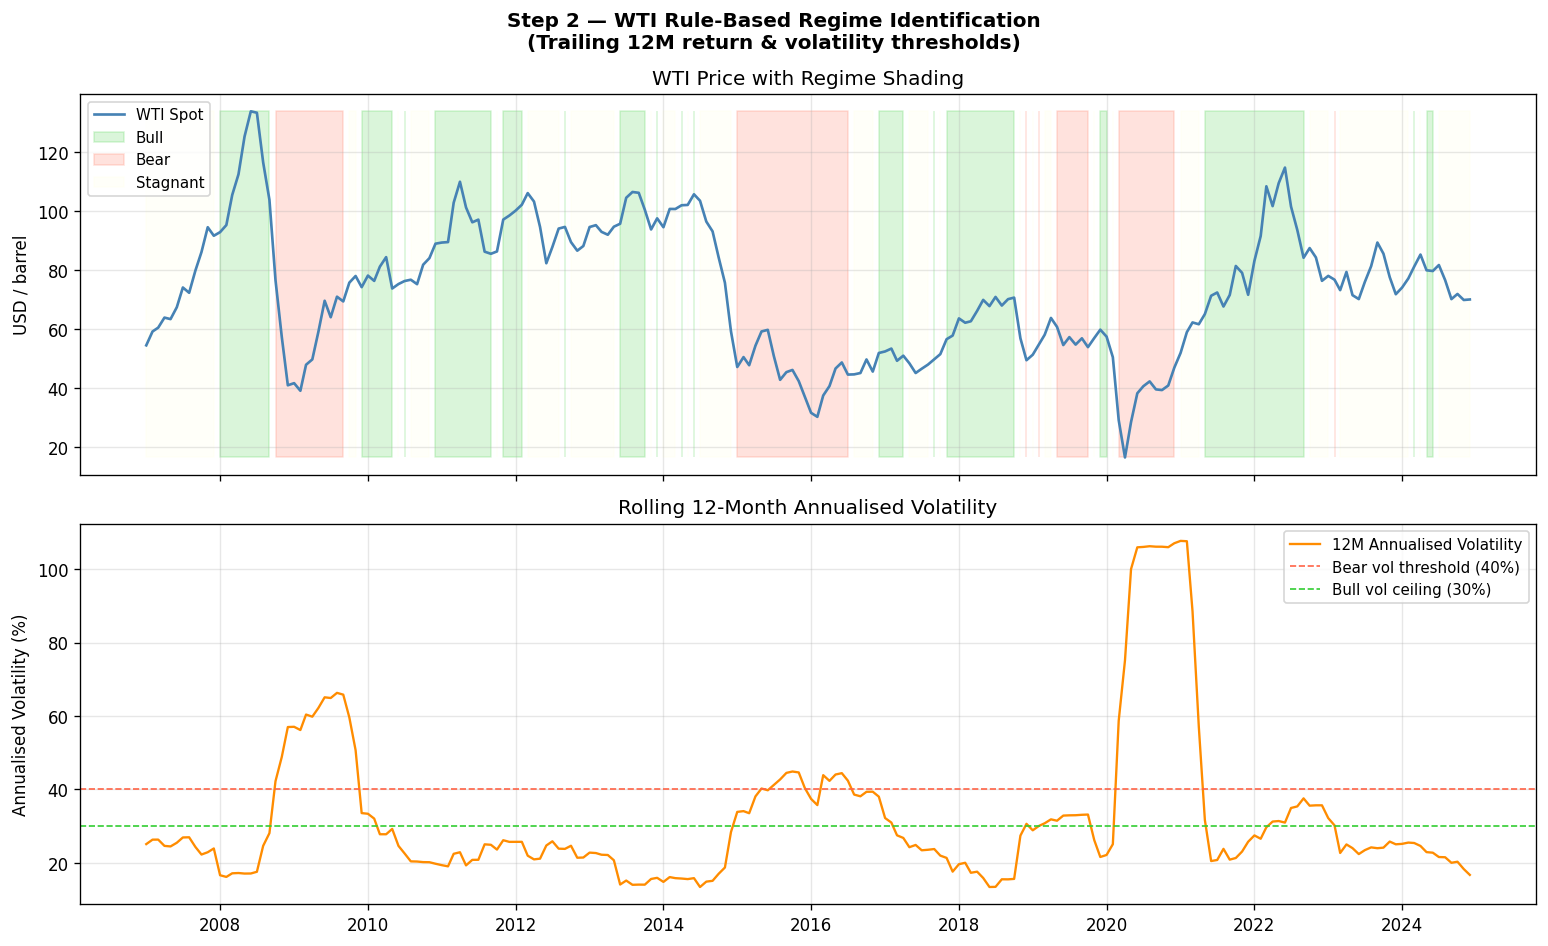


=== Bull Regime ===
  Months : 79
  WTI μ  : $85.42/bbl
  Ret μ  : +1.50%/month
  Vol μ  : 22.9% annualised

=== Bear Regime ===
  Months : 50
  WTI μ  : $48.69/bbl
  Ret μ  : -2.03%/month
  Vol μ  : 54.8% annualised

=== Stagnant Regime ===
  Months : 87
  WTI μ  : $75.74/bbl
  Ret μ  : -0.05%/month
  Vol μ  : 27.8% annualised


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
# Simple rule-based labelling using 12-month trailing returns and volatility.
# This serves as an interpretable benchmark before the HMM.
# ─────────────────────────────────────────────────────────────────────────────

wti_ret12 = df["WTI"].pct_change(12)   # trailing 12-month return
wti_vol12 = df["WTI_vol12"]            # annualised 12-month volatility

bull_mask = (wti_ret12 > 0.10) & (wti_vol12 < 0.40)
bear_mask = (wti_ret12 < -0.10) & (wti_vol12 > 0.30)

regimes_manual = pd.Series("Stagnant", index=df.index)
regimes_manual[bull_mask] = "Bull"
regimes_manual[bear_mask] = "Bear"

print("Rule-Based Regime Counts:")
print(regimes_manual.value_counts().to_string())

# ── Plot ──────────────────────────────────────────────────────────────────────
REGIME_COLORS = {"Bull": "limegreen", "Bear": "tomato", "Stagnant": "lightyellow"}

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
fig.suptitle("Step 2 — WTI Rule-Based Regime Identification\n"
             "(Trailing 12M return & volatility thresholds)",
             fontsize=12, fontweight="bold")

# Price panel
ax = axes[0]
ax.plot(df.index, df["WTI"], color="steelblue", lw=1.6, label="WTI Spot")
for regime, col in REGIME_COLORS.items():
    mask = regimes_manual == regime
    ax.fill_between(df.index, df["WTI"].min(), df["WTI"].max(),
                    where=mask, alpha=0.18, color=col, label=regime)
ax.set_ylabel("USD / barrel")
ax.legend(fontsize=9, loc="upper left")
ax.grid(True, alpha=0.3)
ax.set_title("WTI Price with Regime Shading")

# Volatility panel
ax = axes[1]
ax.plot(df.index, wti_vol12 * 100, color="darkorange", lw=1.4,
        label="12M Annualised Volatility")
ax.axhline(40, color="tomato",    lw=1, ls="--", label="Bear vol threshold (40%)")
ax.axhline(30, color="limegreen", lw=1, ls="--", label="Bull vol ceiling (30%)")
ax.set_ylabel("Annualised Volatility (%)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Rolling 12-Month Annualised Volatility")

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/step2_regimes_manual.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Regime statistics ─────────────────────────────────────────────────────────
def _regime_stats(name):
    """Print summary statistics for a single regime."""
    mask = regimes_manual == name
    sub  = df[mask]
    print(f"\n=== {name} Regime ===")
    print(f"  Months : {mask.sum()}")
    print(f"  WTI μ  : ${sub['WTI'].mean():.2f}/bbl")
    print(f"  Ret μ  : {sub['WTI_ret'].mean()*100:+.2f}%/month")
    print(f"  Vol μ  : {sub['WTI_vol12'].mean()*100:.1f}% annualised")

for regime_name in ["Bull", "Bear", "Stagnant"]:
    _regime_stats(regime_name)


##Step 3 — HMM Definition

In [8]:
print("""
STEP 3 — DEFINITION: HIDDEN MARKOV MODEL
==========================================
Based on Rabiner (1989) and Alvi (2018, Section 2.1.2.1).

An HMM is a doubly-stochastic process defined by the 5-tuple λ = (N, M, A, B, π):

  N  — Number of hidden states  qₜ ∈ {S₁ … Sₙ}
  M  — Observation alphabet size (discrete) or dimensionality (continuous)
  A  — N×N transition matrix:     A[i][j] = P(q_{t+1}=j | qₜ=i)
  B  — Emission function:
         Discrete:   B[j][k] = P(oₜ=vₖ | qₜ=j)
         Gaussian:   B(j,oₜ) = N(oₜ ; μⱼ, Σⱼ)
  π  — Initial distribution:     π[i] = P(q₁=i)

KEY ASSUMPTIONS
  1. First-order Markov: P(qₜ | q₁..q_{t-1}) = P(qₜ | q_{t-1})
  2. Output independence: P(oₜ | q₁..qT, o₁..oT) = P(oₜ | qₜ)
  3. Stationarity: A and B are time-invariant

THE THREE CANONICAL PROBLEMS (Rabiner 1989)
  1. Evaluation  — compute P(O|λ) via Forward algorithm
  2. Decoding    — find most likely Q* via Viterbi algorithm
  3. Learning    — find λ* maximising P(O|λ) via Baum-Welch (EM)

APPLICATION HERE
  Hidden states  = oil market regime (Bull / Bear / Stagnant)
  Observations   = monthly [WTI log-return, 12M annualised vol]
  The HMM learns regime-switching dynamics from data without labels.

REFERENCES
  Rabiner, L.R. (1989). Proc. IEEE 77(2), 257-286.
  Alvi, D.A.   (2018). arXiv:1804.10869.
  Murphy, K.P. (2012). Machine Learning: A Probabilistic Perspective, Ch. 17.
""")



STEP 3 — DEFINITION: HIDDEN MARKOV MODEL
Based on Rabiner (1989) and Alvi (2018, Section 2.1.2.1).

An HMM is a doubly-stochastic process defined by the 5-tuple λ = (N, M, A, B, π):

  N  — Number of hidden states  qₜ ∈ {S₁ … Sₙ}
  M  — Observation alphabet size (discrete) or dimensionality (continuous)
  A  — N×N transition matrix:     A[i][j] = P(q_{t+1}=j | qₜ=i)
  B  — Emission function:
         Discrete:   B[j][k] = P(oₜ=vₖ | qₜ=j)
         Gaussian:   B(j,oₜ) = N(oₜ ; μⱼ, Σⱼ)
  π  — Initial distribution:     π[i] = P(q₁=i)

KEY ASSUMPTIONS
  1. First-order Markov: P(qₜ | q₁..q_{t-1}) = P(qₜ | q_{t-1})
  2. Output independence: P(oₜ | q₁..qT, o₁..oT) = P(oₜ | qₜ)
  3. Stationarity: A and B are time-invariant

THE THREE CANONICAL PROBLEMS (Rabiner 1989)
  1. Evaluation  — compute P(O|λ) via Forward algorithm
  2. Decoding    — find most likely Q* via Viterbi algorithm
  3. Learning    — find λ* maximising P(O|λ) via Baum-Welch (EM)

APPLICATION HERE
  Hidden states  = oil market 

##Step 4 — Design Discussion *(Combined Narrative)*

In [9]:
print("""
STEP 4 — DESIGN DISCUSSION
===========================

4A — MACRO INDICATOR IDENTIFICATION & DATA CLEANING (Student A)
  Following Figure 3.1 of Alvi (2018), we collect five macro/financial
  indicators theoretically linked to crude oil price dynamics:

  • WTI Spot Price    (FRED: WTISPLC)  — target variable
  • US Industrial Production (FRED: INDPRO)  — proxy for aggregate demand
  • US CPI Energy    (FRED: CPIENGSL)  — direct energy price inflation
  • USD Trade-Weighted Index (FRED: DTWEXBGS) — stronger USD depresses oil
  • CBOE VIX         (Yahoo Finance)   — market-wide risk aversion

  Data cleaning: 3×IQR outlier winsorisation, duplicate removal, linear
  interpolation for short gaps. The April 2020 WTI shock was retained.

4B — THE HIDDEN MARKOV PROCESS (Student B)
  The HMM treats the true market regime as a hidden Markov chain.
  The 3×3 transition matrix A learned by Baum-Welch reveals:
    • Persistence of each regime (diagonal A[i][i] values)
    • Transition probabilities between regimes
  Different regimes generate systematically different return/vol patterns.
  Viterbi then labels each month with its most likely regime.

4C — NETWORK TRAINING, TESTING & VALIDATION (Student C)
  The Bayesian network structure is learned via Hill Climb Search with
  BIC scoring:  BIC = ℓ(θ) − (k/2)·log(n)
  The BIC penalty on k parameters prevents overfitting.
  Parameters are estimated by MLE. Validation uses a held-out 20% test set.
  Variable Elimination computes P(Regime | observed macro indicators).
""")



STEP 4 — DESIGN DISCUSSION

4A — MACRO INDICATOR IDENTIFICATION & DATA CLEANING (Student A)
  Following Figure 3.1 of Alvi (2018), we collect five macro/financial
  indicators theoretically linked to crude oil price dynamics:

  • WTI Spot Price    (FRED: WTISPLC)  — target variable
  • US Industrial Production (FRED: INDPRO)  — proxy for aggregate demand
  • US CPI Energy    (FRED: CPIENGSL)  — direct energy price inflation
  • USD Trade-Weighted Index (FRED: DTWEXBGS) — stronger USD depresses oil
  • CBOE VIX         (Yahoo Finance)   — market-wide risk aversion

  Data cleaning: 3×IQR outlier winsorisation, duplicate removal, linear
  interpolation for short gaps. The April 2020 WTI shock was retained.

4B — THE HIDDEN MARKOV PROCESS (Student B)
  The HMM treats the true market regime as a hidden Markov chain.
  The 3×3 transition matrix A learned by Baum-Welch reveals:
    • Persistence of each regime (diagonal A[i][i] values)
    • Transition probabilities between regimes
  Diffe

##Step 6A — Time-Series Transformation

ADF Test — WTI Log Returns:
  Test statistic : -9.7807
  p-value        : 0.000000
  Critical values: {'1%': np.float64(-3.4612821203214907), '5%': np.float64(-2.875142613826617), '10%': np.float64(-2.574020122281422)}
  Decision       : Reject H₀ → STATIONARY ✓

Feature matrix X shape: (216, 2)
  Col 0: WTI log-return (monthly)  — standardised
  Col 1: WTI 12M annualised vol     — standardised


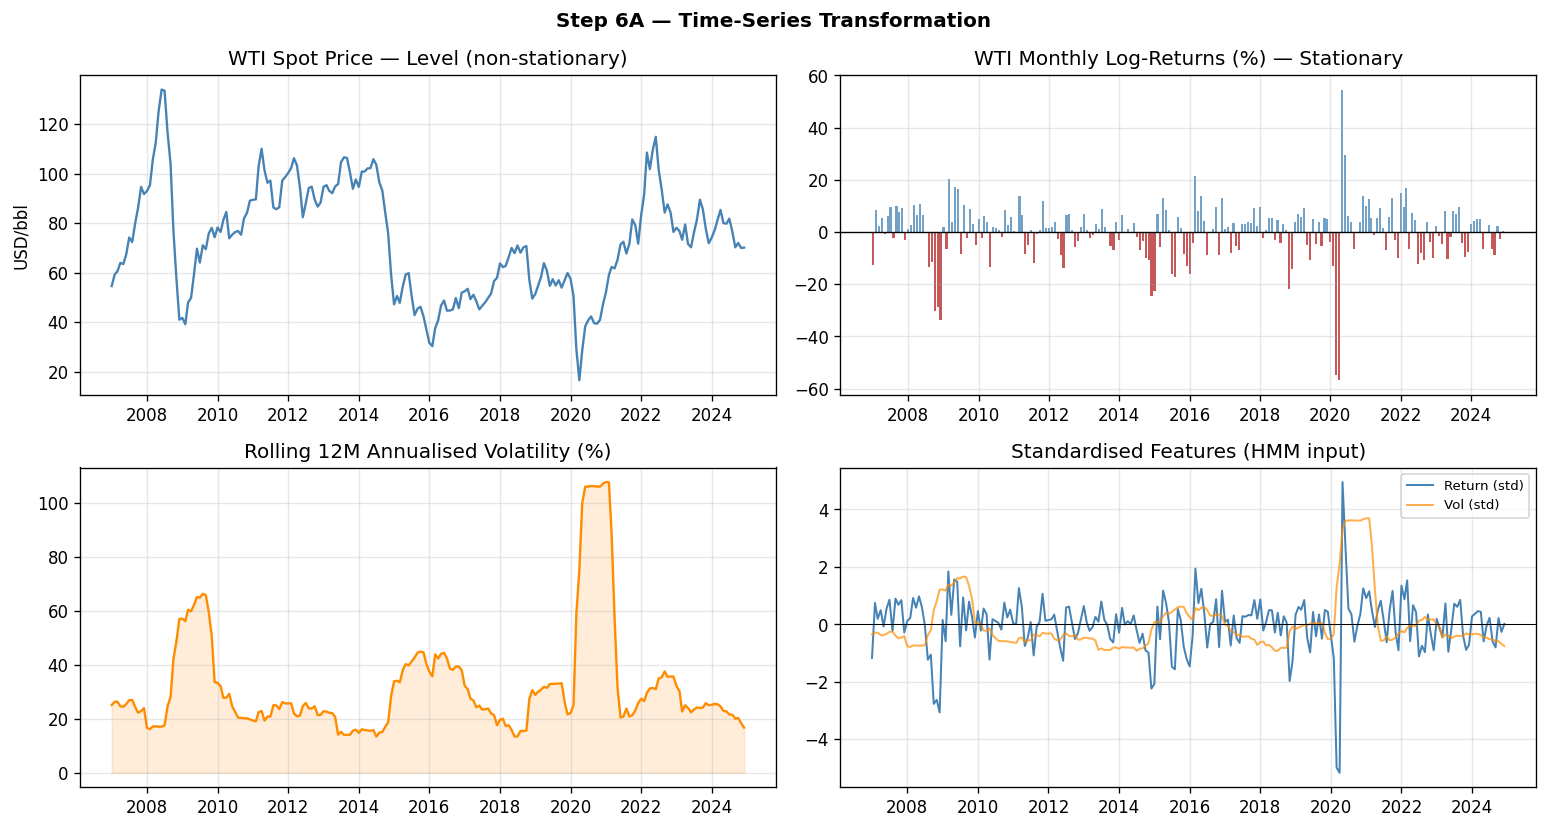

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
# Raw price levels are non-stationary. HMM assumes stationary emissions.
# Transformation pipeline:
#   1. Log-returns:   rₜ = log(Pₜ / P_{t-1})
#   2. Standardise:   zₜ = (rₜ − μ̂) / σ̂
#   3. Feature matrix: X = [WTI_ret, WTI_vol12]
#   4. ADF test confirms stationarity
# ─────────────────────────────────────────────────────────────────────────────

# ── Stationarity check ────────────────────────────────────────────────────────
adf_stat, p_val, _, _, crit_vals, _ = adfuller(df["WTI_ret"].dropna(), autolag="AIC")
print("ADF Test — WTI Log Returns:")
print(f"  Test statistic : {adf_stat:.4f}")
print(f"  p-value        : {p_val:.6f}")
print(f"  Critical values: {crit_vals}")
decision = "Reject H₀ → STATIONARY ✓" if p_val < 0.05 else "Fail to reject H₀ → may be non-stationary"
print(f"  Decision       : {decision}")

# ── Build feature matrix ──────────────────────────────────────────────────────
feature_df  = df[["WTI_ret", "WTI_vol12"]].dropna()
hmm_dates   = feature_df.index
scaler      = StandardScaler()
X_raw       = feature_df.values
X_std       = scaler.fit_transform(X_raw)

print(f"\nFeature matrix X shape: {X_std.shape}")
print("  Col 0: WTI log-return (monthly)  — standardised")
print("  Col 1: WTI 12M annualised vol     — standardised")

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
fig.suptitle("Step 6A — Time-Series Transformation", fontsize=12, fontweight="bold")

axes[0, 0].plot(df.index, df["WTI"], color="steelblue", lw=1.4)
axes[0, 0].set_title("WTI Spot Price — Level (non-stationary)")
axes[0, 0].set_ylabel("USD/bbl")

bar_colors = ["firebrick" if r < 0 else "steelblue" for r in X_raw[:, 0]]
axes[0, 1].bar(hmm_dates, X_raw[:, 0] * 100, color=bar_colors, width=22, alpha=0.75)
axes[0, 1].axhline(0, color="black", lw=0.8)
axes[0, 1].set_title("WTI Monthly Log-Returns (%) — Stationary")

axes[1, 0].plot(hmm_dates, X_raw[:, 1] * 100, color="darkorange", lw=1.4)
axes[1, 0].fill_between(hmm_dates, 0, X_raw[:, 1] * 100, alpha=0.15, color="darkorange")
axes[1, 0].set_title("Rolling 12M Annualised Volatility (%)")

axes[1, 1].plot(hmm_dates, X_std[:, 0], color="steelblue",  lw=1.2, label="Return (std)")
axes[1, 1].plot(hmm_dates, X_std[:, 1], color="darkorange", lw=1.2, alpha=0.7, label="Vol (std)")
axes[1, 1].axhline(0, color="black", lw=0.6)
axes[1, 1].set_title("Standardised Features (HMM input)")
axes[1, 1].legend(fontsize=8)

for ax in axes.flat:
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/step6a_transformation.png", dpi=150, bbox_inches="tight")
plt.show()


##Step 6B — Parameter Learning via Baum-Welch

In [11]:
# ─────────────────────────────────────────────────────────────────────────────
# Fit a 3-state Gaussian HMM with multiple random restarts.
# Keep the model with the highest log-likelihood to avoid local optima.
#
# Hyperparameters:
#   n_components    = 3       (Bull, Bear, Stagnant)
#   covariance_type = 'full'  (each state has own 2×2 covariance)
#   n_iter          = 200
#   n_restarts      = 10
# ─────────────────────────────────────────────────────────────────────────────

best_model, best_loglik = None, -np.inf

for seed in range(10):
    try:
        model = GaussianHMM(
            n_components=3, covariance_type="full",
            n_iter=200, tol=1e-4, random_state=seed, verbose=False
        )
        model.fit(X_std)
        ll = model.score(X_std)
        if ll > best_loglik:
            best_loglik, best_model = ll, model
    except Exception:
        continue

hmm_model = best_model
print(f"Best log-likelihood : {best_loglik:.4f}")
print(f"EM iterations ran   : {hmm_model.monitor_.iter}")
print(f"Converged           : {hmm_model.monitor_.converged}")

print("\nInitial state probabilities π:")
for i, p in enumerate(hmm_model.startprob_):
    print(f"  State {i}: {p:.4f}")

print("\nTransition matrix A:")
header = "  " + "  ".join(f"→ S{j}" for j in range(3))
print(header)
for i in range(3):
    row = "  ".join(f"{hmm_model.transmat_[i, j]:.4f}" for j in range(3))
    print(f"  S{i}: {row}")

means_orig = scaler.inverse_transform(hmm_model.means_)
print("\nEmission means (original units):")
for i in range(3):
    print(f"  State {i}: monthly_ret={means_orig[i, 0]*100:.2f}%  "
          f"ann_vol={means_orig[i, 1]*100:.1f}%")


Best log-likelihood : -305.9770
EM iterations ran   : 20
Converged           : True

Initial state probabilities π:
  State 0: 0.0000
  State 1: 1.0000
  State 2: 0.0000

Transition matrix A:
  → S0  → S1  → S2
  S0: 0.9151  0.0849  0.0000
  S1: 0.0235  0.9605  0.0160
  S2: 0.0726  0.0000  0.9274

Emission means (original units):
  State 0: monthly_ret=-1.16%  ann_vol=35.1%
  State 1: monthly_ret=0.73%  ann_vol=21.3%
  State 2: monthly_ret=-0.44%  ann_vol=76.7%


##Step 6C — Viterbi Decoding

In [12]:
# ─────────────────────────────────────────────────────────────────────────────
# Apply the Viterbi algorithm (via hmmlearn) to decode the most likely
# hidden-state sequence Q* from the observed return/vol series.
# ─────────────────────────────────────────────────────────────────────────────

viterbi_states = hmm_model.predict(X_std)
state_series   = pd.Series(viterbi_states, index=hmm_dates, name="HMM_State")

print("Viterbi Decoding — State Frequency Summary:")
for s, cnt in state_series.value_counts().sort_index().items():
    print(f"  State {s}: {cnt:3d} months ({cnt / len(state_series) * 100:.1f}%)")


Viterbi Decoding — State Frequency Summary:
  State 0:  59 months (27.3%)
  State 1: 129 months (59.7%)
  State 2:  28 months (13.0%)


##Step 7 — Latent Meaning of Hidden States

STEP 7 — Latent Meaning of Hidden States

  State 0  →  'Bear' Regime
    Months          : 59 (27.3%)
    Mean WTI price  : $61.71/bbl
    Mean monthly ret: -1.49%
    Mean ann. vol   : 35.1%
    Mean VIX        : 18.7
    Mean IndPro Δ   : -0.037%

  State 1  →  'Bull' Regime
    Months          : 129 (59.7%)
    Mean WTI price  : $82.88/bbl
    Mean monthly ret: +0.84%
    Mean ann. vol   : 21.3%
    Mean VIX        : 17.9
    Mean IndPro Δ   : +0.089%

  State 2  →  'Stagnant' Regime
    Months          : 28 (13.0%)
    Mean WTI price  : $51.39/bbl
    Mean monthly ret: -0.31%
    Mean ann. vol   : 77.0%
    Mean VIX        : 32.8
    Mean IndPro Δ   : -0.327%


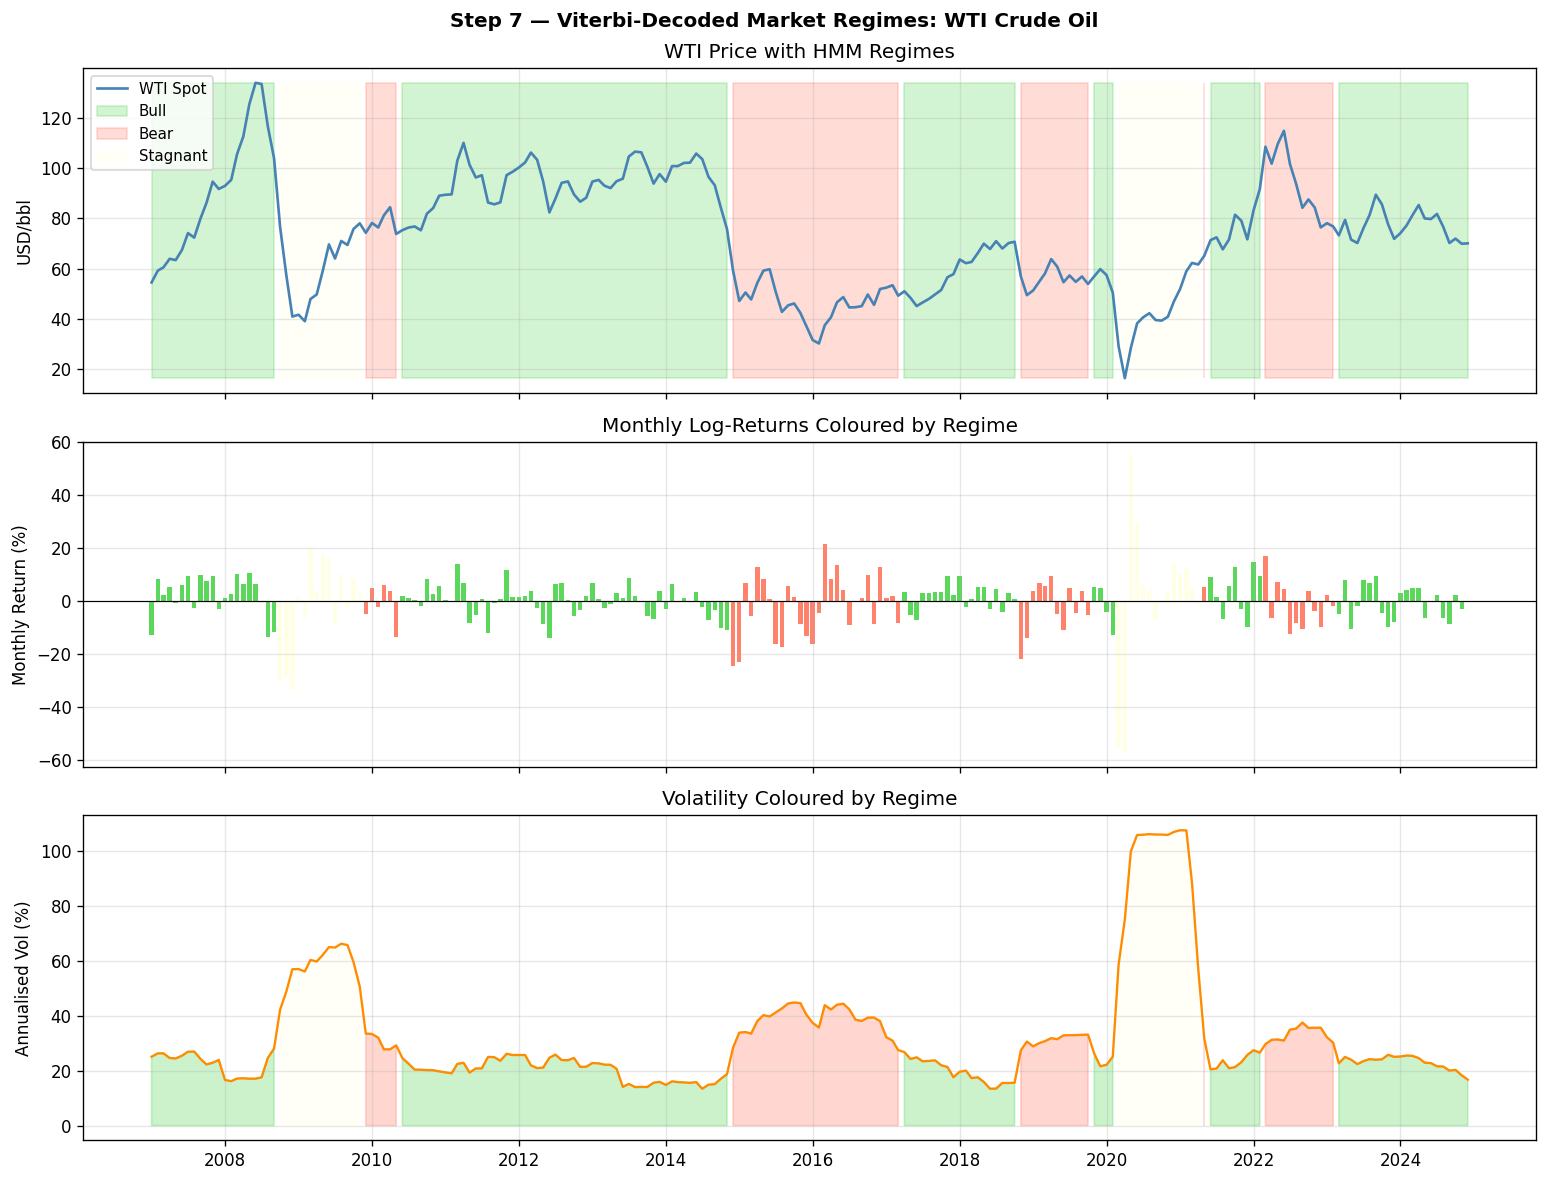

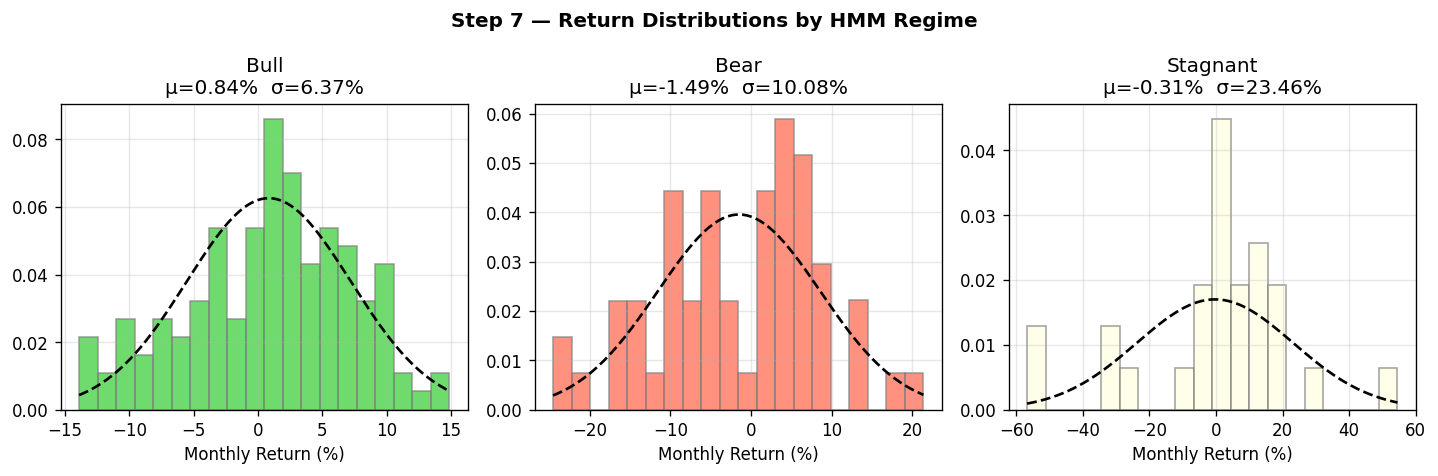

In [13]:
# ─────────────────────────────────────────────────────────────────────────────
# Assign economic labels to the learned HMM states by examining mean returns,
# volatility, VIX, and industrial production across each state cluster.
# ─────────────────────────────────────────────────────────────────────────────

df_hmm = (
    df[["WTI", "WTI_ret", "WTI_vol12", "VIX", "IndPro_ret"]]
    .reindex(hmm_dates)
    .assign(State=viterbi_states)
)

# Compute per-state statistics
state_stats = {
    s: {
        "count":    (df_hmm["State"] == s).sum(),
        "wti_mean": df_hmm.loc[df_hmm["State"] == s, "WTI"].mean(),
        "ret_mean": df_hmm.loc[df_hmm["State"] == s, "WTI_ret"].mean() * 100,
        "vol_mean": df_hmm.loc[df_hmm["State"] == s, "WTI_vol12"].mean() * 100,
        "vix_mean": df_hmm.loc[df_hmm["State"] == s, "VIX"].mean(),
        "ip_mean":  df_hmm.loc[df_hmm["State"] == s, "IndPro_ret"].mean() * 100,
    }
    for s in range(3)
}

# Label states by mean return rank
sorted_states = sorted(state_stats.items(), key=lambda x: x[1]["ret_mean"])
LABEL_MAP = {sorted_states[0][0]: "Bear",
             sorted_states[1][0]: "Stagnant",
             sorted_states[2][0]: "Bull"}
df_hmm["Regime"] = df_hmm["State"].map(LABEL_MAP)

print("STEP 7 — Latent Meaning of Hidden States")
print("=" * 55)
for s in range(3):
    st = state_stats[s]
    print(f"\n  State {s}  →  '{LABEL_MAP[s]}' Regime")
    print(f"    Months          : {st['count']} ({st['count']/len(df_hmm)*100:.1f}%)")
    print(f"    Mean WTI price  : ${st['wti_mean']:.2f}/bbl")
    print(f"    Mean monthly ret: {st['ret_mean']:+.2f}%")
    print(f"    Mean ann. vol   : {st['vol_mean']:.1f}%")
    print(f"    Mean VIX        : {st['vix_mean']:.1f}")
    print(f"    Mean IndPro Δ   : {st['ip_mean']:+.3f}%")

# ── Visualisation ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
fig.suptitle("Step 7 — Viterbi-Decoded Market Regimes: WTI Crude Oil",
             fontsize=12, fontweight="bold")

# Price
ax = axes[0]
ax.plot(df_hmm.index, df_hmm["WTI"], color="steelblue", lw=1.6, label="WTI Spot")
for regime, col in REGIME_COLORS.items():
    mask = df_hmm["Regime"] == regime
    ax.fill_between(df_hmm.index, df_hmm["WTI"].min(), df_hmm["WTI"].max(),
                    where=mask, alpha=0.22, color=col, label=regime)
ax.set_ylabel("USD/bbl")
ax.legend(fontsize=9, loc="upper left")
ax.set_title("WTI Price with HMM Regimes")

# Returns bar
ax = axes[1]
bar_cols = [REGIME_COLORS.get(df_hmm.loc[d, "Regime"], "grey") for d in df_hmm.index]
ax.bar(df_hmm.index, df_hmm["WTI_ret"] * 100, color=bar_cols, width=22, alpha=0.8)
ax.axhline(0, color="black", lw=0.7)
ax.set_ylabel("Monthly Return (%)")
ax.set_title("Monthly Log-Returns Coloured by Regime")

# Volatility
ax = axes[2]
ax.plot(df_hmm.index, df_hmm["WTI_vol12"] * 100, color="darkorange", lw=1.4)
for regime, col in REGIME_COLORS.items():
    mask = df_hmm["Regime"] == regime
    ax.fill_between(df_hmm.index, 0, df_hmm["WTI_vol12"] * 100,
                    where=mask, alpha=0.25, color=col)
ax.set_ylabel("Annualised Vol (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Volatility Coloured by Regime")

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/step7_hmm_regimes.png", dpi=150, bbox_inches="tight")
plt.show()

# Return distributions
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle("Step 7 — Return Distributions by HMM Regime", fontsize=12, fontweight="bold")
for ax, (regime, col) in zip(axes, REGIME_COLORS.items()):
    data_r = df_hmm[df_hmm["Regime"] == regime]["WTI_ret"] * 100
    mu, sg = data_r.mean(), data_r.std()
    ax.hist(data_r, bins=20, color=col, alpha=0.7, edgecolor="grey", density=True)
    xs = np.linspace(data_r.min(), data_r.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sg), "k--", lw=1.6)
    ax.set_title(f"{regime}\nμ={mu:.2f}%  σ={sg:.2f}%")
    ax.set_xlabel("Monthly Return (%)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/step7_regime_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


##Step 8 — Hill Climb Search: Theory (Section 4.2.6)

In [14]:
print("""
STEP 8 — HILL CLIMB SEARCH FOR BAYESIAN NETWORK STRUCTURE
===========================================================
(Section 4.2.6 summary — Alvi 2018)

OBJECTIVE
  Find the DAG G that maximises BIC = ℓ(θ) − (k/2)·log(n)
  where k = number of parameters, n = sample size.
  The BIC penalty discourages unnecessary edges (overfitting).

ALGORITHM
  1. Start from an empty (or random) DAG.
  2. At each iteration, evaluate all single-edge operations:
       ADD edge u→v, REMOVE edge, or REVERSE edge.
  3. Apply the operation with the greatest BIC gain.
  4. Maintain a Tabu list to avoid revisiting recent structures.
  5. Stop when no single operation improves BIC.

RESULT
  The learned DAG encodes conditional independence.
  CPDs are then estimated by Maximum Likelihood.

VARIABLES IN THIS PROJECT'S NETWORK
  • WTI_Regime    (target:  Bull / Bear / Stagnant — from HMM Viterbi)
  • VIX_Level     (discretised: Low / Medium / High)
  • DXY_Trend     (Up / Flat / Down)
  • IndPro_Trend  (Rising / Flat / Falling)
  • CPI_Nrg_Trend (Rising / Flat / Falling)
""")



STEP 8 — HILL CLIMB SEARCH FOR BAYESIAN NETWORK STRUCTURE
(Section 4.2.6 summary — Alvi 2018)

OBJECTIVE
  Find the DAG G that maximises BIC = ℓ(θ) − (k/2)·log(n)
  where k = number of parameters, n = sample size.
  The BIC penalty discourages unnecessary edges (overfitting).

ALGORITHM
  1. Start from an empty (or random) DAG.
  2. At each iteration, evaluate all single-edge operations:
       ADD edge u→v, REMOVE edge, or REVERSE edge.
  3. Apply the operation with the greatest BIC gain.
  4. Maintain a Tabu list to avoid revisiting recent structures.
  5. Stop when no single operation improves BIC.

RESULT
  The learned DAG encodes conditional independence.
  CPDs are then estimated by Maximum Likelihood.

VARIABLES IN THIS PROJECT'S NETWORK
  • WTI_Regime    (target:  Bull / Bear / Stagnant — from HMM Viterbi)
  • VIX_Level     (discretised: Low / Medium / High)
  • DXY_Trend     (Up / Flat / Down)
  • IndPro_Trend  (Rising / Flat / Falling)
  • CPI_Nrg_Trend (Rising / Flat / Fall

##Step 9A — Bayesian Network Structure Search

In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# Discretise continuous variables into 3 ordered categories using
# quantile-based thresholds (33rd and 67th percentile).
# ─────────────────────────────────────────────────────────────────────────────

def discretise_3(series: pd.Series, labels: list) -> pd.Series:
    """Split a series into 3 equally-sized quantile bands and assign labels."""
    q33, q67 = series.quantile(0.33), series.quantile(0.67)
    return series.map(lambda v: labels[0] if v < q33 else (labels[1] if v < q67 else labels[2]))


bn_data = pd.DataFrame({
    "WTI_Regime":    df_hmm["Regime"],
    "VIX_Level":     discretise_3(df_hmm["VIX"], ["Low", "Medium", "High"]),
    "DXY_Trend":     discretise_3(df["DXY_ret"].reindex(hmm_dates), ["Down", "Flat", "Up"]),
    "IndPro_Trend":  discretise_3(df["IndPro_ret"].reindex(hmm_dates), ["Falling", "Flat", "Rising"]),
    "CPI_Nrg_Trend": discretise_3(
        df["CPI_Nrg"].pct_change().reindex(hmm_dates), ["Falling", "Flat", "Rising"]
    ),
}, index=hmm_dates).dropna()

print(f"BN dataset: {bn_data.shape}")
print(bn_data.head(3).to_string())
print("\nValue counts per variable:")
for col in bn_data.columns:
    print(f"  {col}: {bn_data[col].value_counts().to_dict()}")

# ── Hill Climb structure search ───────────────────────────────────────────────
print("\nRunning Hill Climb structure search (BIC score) ...")
hc = HillClimbSearch(bn_data)

try:
    # pgmpy >= 0.1.23 API
    best_dag = hc.estimate(
        scoring_method="bic-d", max_indegree=3,
        max_iter=500, tabu_length=10, show_progress=False
    )
    print("  Completed (pgmpy >= 0.1.23 API)")
except TypeError:
    # Legacy API
    best_dag = hc.estimate(
        max_indegree=3, max_iter=500, tabu_length=10, show_progress=False
    )
    print("  Completed (legacy pgmpy API)")

print(f"\nLearned DAG edges ({len(best_dag.edges())} total):")
for u, v in sorted(best_dag.edges()):
    print(f"  {u}  →  {v}")


BN dataset: (216, 5)
           WTI_Regime VIX_Level DXY_Trend IndPro_Trend CPI_Nrg_Trend
2007-01-01       Bull       Low        Up      Falling        Rising
2007-02-01       Bull       Low      Down       Rising          Flat
2007-03-01       Bull       Low      Down         Flat        Rising

Value counts per variable:
  WTI_Regime: {'Bull': 129, 'Bear': 59, 'Stagnant': 28}
  VIX_Level: {'Medium': 74, 'Low': 71, 'High': 71}
  DXY_Trend: {'Flat': 74, 'Up': 71, 'Down': 71}
  IndPro_Trend: {'Flat': 74, 'Falling': 71, 'Rising': 71}
  CPI_Nrg_Trend: {'Flat': 73, 'Rising': 72, 'Falling': 71}

Running Hill Climb structure search (BIC score) ...
  Completed (pgmpy >= 0.1.23 API)

Learned DAG edges (1 total):
  VIX_Level  →  WTI_Regime


##Step 9B — CPD Fitting, Validation & Inference

In [16]:
# ── Build and fit the Bayesian Network ───────────────────────────────────────
bn_model = DiscreteBayesianNetwork(best_dag.edges())
for col in bn_data.columns:
    if col not in bn_model.nodes():
        bn_model.add_node(col)

bn_model.fit(bn_data, estimator=DiscreteMLE())

print("CPD Summary (marginal distribution for each node):")
for node in bn_model.nodes():
    cpd = bn_model.get_cpds(node)
    if cpd is not None:
        print(f"\n  {node}  (parents: {cpd.variables[1:]})")
        df_cpd = pd.DataFrame(
            cpd.get_values(),
            index=cpd.state_names[node],
            columns=range(cpd.get_values().shape[1]),
        )
        print(df_cpd.round(3).to_string())

# ── Train / test split (most recent 20% held out) ────────────────────────────
split_idx   = int(len(bn_data) * 0.80)
df_train    = bn_data.iloc[:split_idx]
df_test     = bn_data.iloc[split_idx:]

bn_train = DiscreteBayesianNetwork(best_dag.edges())
for col in bn_data.columns:
    if col not in bn_train.nodes():
        bn_train.add_node(col)
bn_train.fit(df_train, estimator=DiscreteMLE())

print(f"\nValidation split: train={len(df_train)}  test={len(df_test)} "
      f"({df_test.index[0].date()} → {df_test.index[-1].date()})")

# ── Inference: P(WTI_Regime | macro evidence) ─────────────────────────────────
try:
    infer   = VariableElimination(bn_train)
    parents = list(bn_model.get_parents("WTI_Regime"))
    evidence = {}
    if "VIX_Level" in parents:   evidence["VIX_Level"]  = "High"
    if "DXY_Trend" in parents:   evidence["DXY_Trend"]  = "Up"

    query = infer.query(["WTI_Regime"], evidence=evidence or None,
                        show_progress=False)

    label = f"P(WTI_Regime | {evidence})" if evidence else "Marginal P(WTI_Regime)"
    print(f"\nInference — {label}:")
    for regime, prob in zip(query.state_names["WTI_Regime"], query.values):
        print(f"  {regime:<12}: {prob:.4f}")
except Exception as e:
    print(f"\nInference note: {e}")


CPD Summary (marginal distribution for each node):

  VIX_Level  (parents: [])
            0
High    0.329
Low     0.329
Medium  0.343

  WTI_Regime  (parents: ['VIX_Level'])
              0      1      2
Bear      0.225  0.296  0.297
Bull      0.423  0.704  0.662
Stagnant  0.352  0.000  0.041

  DXY_Trend  (parents: [])
          0
Down  0.329
Flat  0.343
Up    0.329

  IndPro_Trend  (parents: [])
             0
Falling  0.329
Flat     0.343
Rising   0.329

  CPI_Nrg_Trend  (parents: [])
             0
Falling  0.329
Flat     0.338
Rising   0.333

Validation split: train=172  test=44 (2021-05-01 → 2024-12-01)

Inference — P(WTI_Regime | {'VIX_Level': 'High'}):
  Bear        : 0.1379
  Bull        : 0.4310
  Stagnant    : 0.4310


##Step 9C — Bayesian Network DAG Visualisation

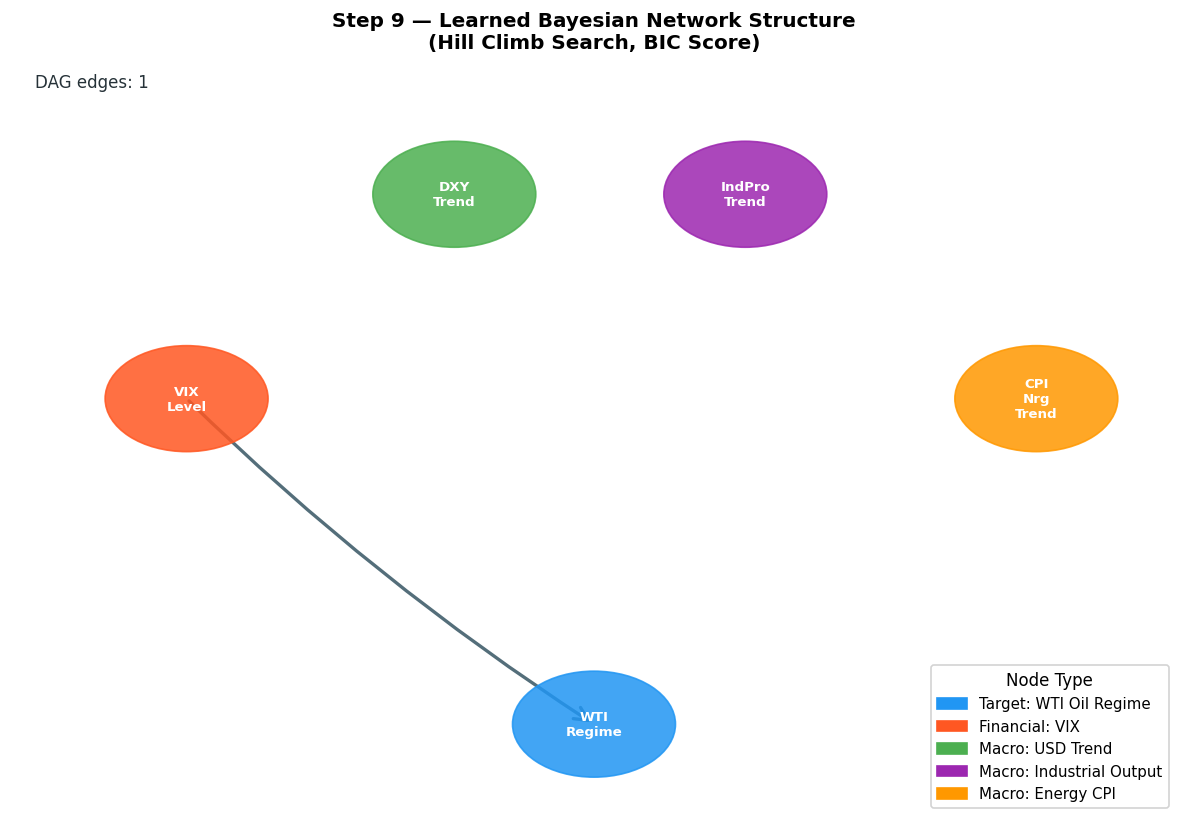

In [17]:
# Fixed positions keep the target node (WTI_Regime) at the bottom centre,
# with macro/financial drivers arranged above it.

NODE_POSITIONS = {
    "WTI_Regime":    (0.50, 0.12),
    "VIX_Level":     (0.15, 0.55),
    "DXY_Trend":     (0.38, 0.82),
    "IndPro_Trend":  (0.63, 0.82),
    "CPI_Nrg_Trend": (0.88, 0.55),
}
NODE_COLORS = {
    "WTI_Regime":    "#2196F3",
    "VIX_Level":     "#FF5722",
    "DXY_Trend":     "#4CAF50",
    "IndPro_Trend":  "#9C27B0",
    "CPI_Nrg_Trend": "#FF9800",
}

fig, ax = plt.subplots(figsize=(10, 7))
ax.set_facecolor("#f5f7fa")
ax.axis("off")
ax.set_title("Step 9 — Learned Bayesian Network Structure\n"
             "(Hill Climb Search, BIC Score)",
             fontsize=12, fontweight="bold")

# Draw edges
for u, v in best_dag.edges():
    if u in NODE_POSITIONS and v in NODE_POSITIONS:
        x0, y0 = NODE_POSITIONS[u]
        x1, y1 = NODE_POSITIONS[v]
        ax.annotate(
            "", xy=(x1, y1), xytext=(x0, y0),
            arrowprops=dict(arrowstyle="->", color="#546E7A",
                            lw=2, mutation_scale=20,
                            connectionstyle="arc3,rad=0.05"),
            xycoords="axes fraction", textcoords="axes fraction",
        )

# Draw nodes
for node, (x, y) in NODE_POSITIONS.items():
    col = NODE_COLORS.get(node, "grey")
    ax.add_patch(plt.Circle((x, y), 0.07, color=col, alpha=0.85,
                             transform=ax.transAxes, zorder=4))
    ax.text(x, y, node.replace("_", "\n"), ha="center", va="center",
            fontsize=8, color="white", fontweight="bold",
            transform=ax.transAxes, zorder=5)

legend_handles = [
    mpatches.Patch(color="#2196F3", label="Target: WTI Oil Regime"),
    mpatches.Patch(color="#FF5722", label="Financial: VIX"),
    mpatches.Patch(color="#4CAF50", label="Macro: USD Trend"),
    mpatches.Patch(color="#9C27B0", label="Macro: Industrial Output"),
    mpatches.Patch(color="#FF9800", label="Macro: Energy CPI"),
]
ax.legend(handles=legend_handles, loc="lower right",
          fontsize=9, framealpha=0.85, title="Node Type")
ax.text(0.02, 0.98, f"DAG edges: {len(best_dag.edges())}",
        transform=ax.transAxes, fontsize=10, va="top", color="#263238")

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/step9_bayesian_network.png", dpi=150, bbox_inches="tight")
plt.show()


##Summary Dashboard

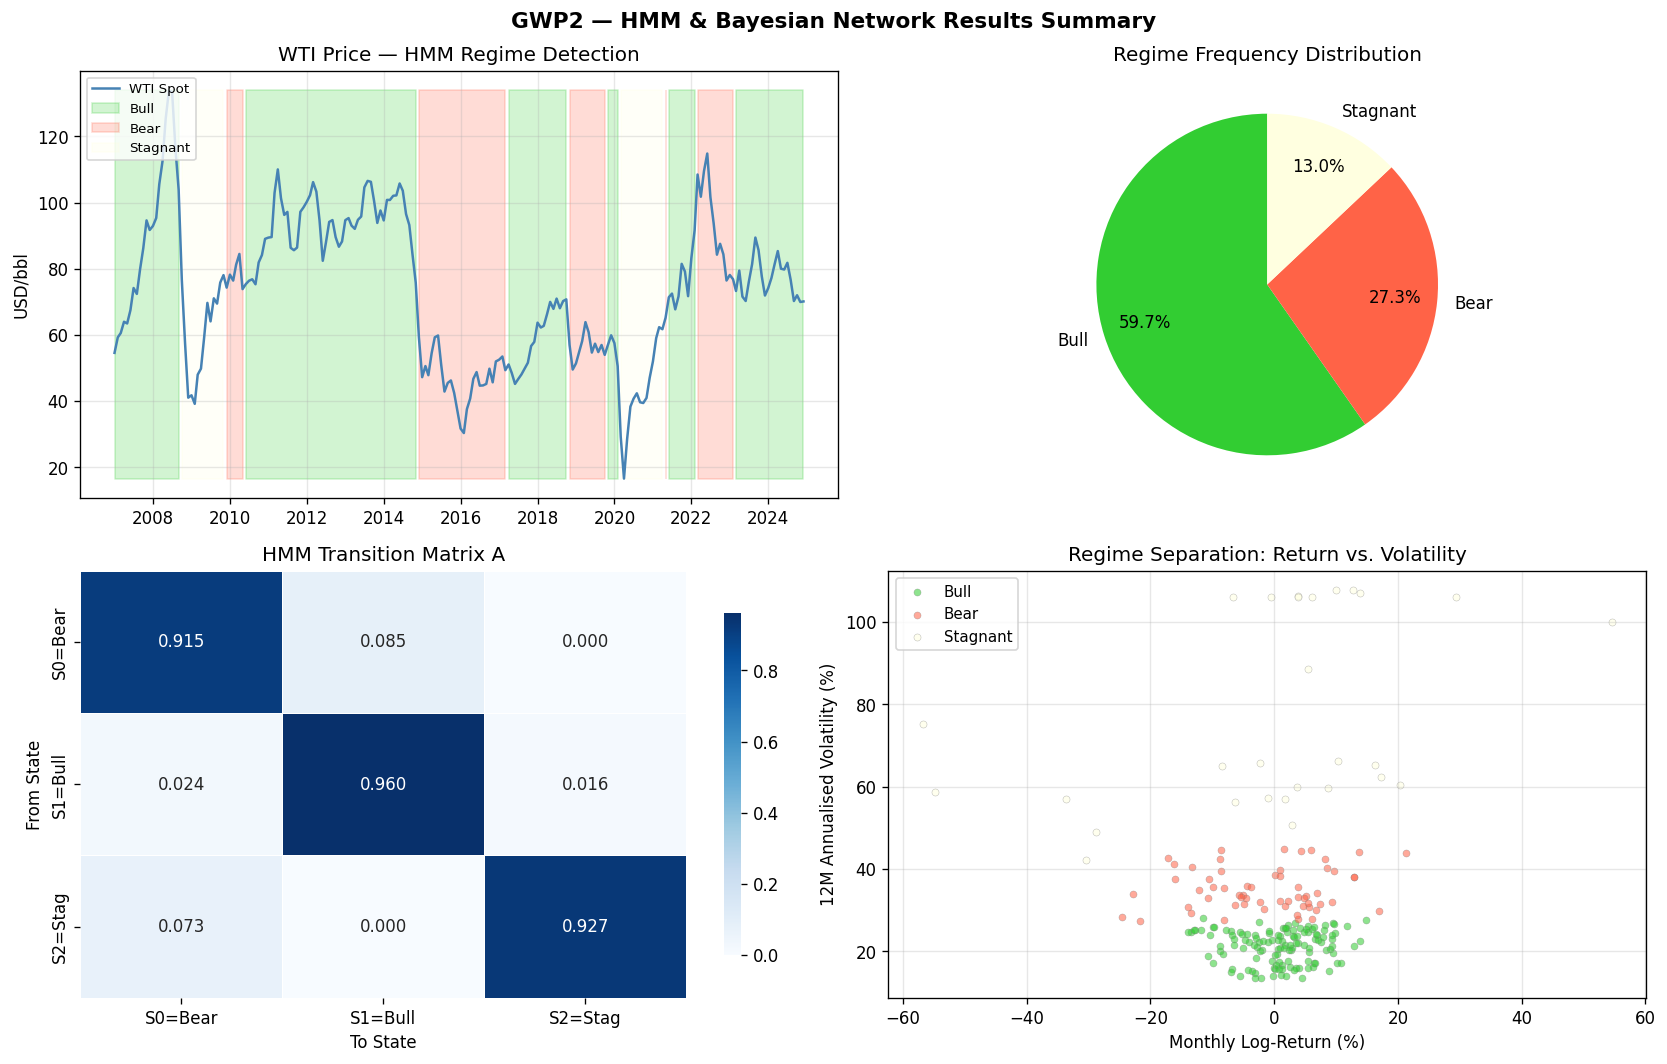

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("GWP2 — HMM & Bayesian Network Results Summary",
             fontsize=13, fontweight="bold")

# 1. WTI price with HMM regimes
ax = axes[0, 0]
ax.plot(df_hmm.index, df_hmm["WTI"], color="steelblue", lw=1.5, label="WTI Spot")
for regime, col in REGIME_COLORS.items():
    mask = df_hmm["Regime"] == regime
    ax.fill_between(df_hmm.index, df_hmm["WTI"].min(), df_hmm["WTI"].max(),
                    where=mask, alpha=0.22, color=col, label=regime)
ax.set_title("WTI Price — HMM Regime Detection")
ax.set_ylabel("USD/bbl")
ax.legend(fontsize=8, loc="upper left")
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# 2. Regime frequency pie
ax = axes[0, 1]
counts = df_hmm["Regime"].value_counts()
ax.pie(counts, labels=counts.index,
       colors=[REGIME_COLORS[r] for r in counts.index],
       autopct="%1.1f%%", startangle=90, pctdistance=0.75)
ax.set_title("Regime Frequency Distribution")

# 3. Transition matrix heatmap
ax = axes[1, 0]
tm = pd.DataFrame(
    hmm_model.transmat_,
    index=[f"S{i}={LABEL_MAP[i][:4]}" for i in range(3)],
    columns=[f"S{j}={LABEL_MAP[j][:4]}" for j in range(3)],
)
sns.heatmap(tm, ax=ax, annot=True, fmt=".3f", cmap="Blues",
            linewidths=0.5, cbar_kws={"shrink": 0.8})
ax.set_title("HMM Transition Matrix A")
ax.set_xlabel("To State")
ax.set_ylabel("From State")

# 4. Regime scatter: return vs. volatility
ax = axes[1, 1]
for regime, col in REGIME_COLORS.items():
    sub = df_hmm[df_hmm["Regime"] == regime]
    ax.scatter(sub["WTI_ret"] * 100, sub["WTI_vol12"] * 100,
               color=col, alpha=0.55, s=18, label=regime,
               edgecolors="grey", linewidths=0.3)
ax.set_xlabel("Monthly Log-Return (%)")
ax.set_ylabel("12M Annualised Volatility (%)")
ax.set_title("Regime Separation: Return vs. Volatility")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/gwp2_summary_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()


##Final Execution Report

In [19]:
print("=" * 65)
print("GWP 2 — FINAL EXECUTION SUMMARY")
print("=" * 65)
print(f"""
  Study period       : {START} → {END}
  HMM observations   : {len(X_std)} monthly periods
  HMM states (N)     : 3  (Bull, Bear, Stagnant)
  HMM features       : WTI log-return, 12M annualised vol
  Best log-likelihood: {best_loglik:.4f}
  HMM converged      : {hmm_model.monitor_.converged}

  Regime distribution (Viterbi):
    Bull      : {(df_hmm['Regime'] == 'Bull').sum()} months
    Bear      : {(df_hmm['Regime'] == 'Bear').sum()} months
    Stagnant  : {(df_hmm['Regime'] == 'Stagnant').sum()} months

  Bayesian Network:
    Variables : {list(bn_data.columns)}
    Edges     : {list(best_dag.edges())}
    Scoring   : BIC (Hill Climb Search)
    CPDs fit  : Maximum Likelihood Estimation

  Plots saved to: {PLOTS_DIR}
""")
print("Steps completed: 1A, 1B, 1C, 2, 3, 4, 6A, 6B, 6C, 7, 8, 9A, 9B, 9C")


GWP 2 — FINAL EXECUTION SUMMARY

  Study period       : 2005-01-01 → 2024-12-31
  HMM observations   : 216 monthly periods
  HMM states (N)     : 3  (Bull, Bear, Stagnant)
  HMM features       : WTI log-return, 12M annualised vol
  Best log-likelihood: -305.9770
  HMM converged      : True

  Regime distribution (Viterbi):
    Bull      : 129 months
    Bear      : 59 months
    Stagnant  : 28 months

  Bayesian Network:
    Variables : ['WTI_Regime', 'VIX_Level', 'DXY_Trend', 'IndPro_Trend', 'CPI_Nrg_Trend']
    Edges     : [('VIX_Level', 'WTI_Regime')]
    Scoring   : BIC (Hill Climb Search)
    CPDs fit  : Maximum Likelihood Estimation

  Plots saved to: /content/plots

Steps completed: 1A, 1B, 1C, 2, 3, 4, 6A, 6B, 6C, 7, 8, 9A, 9B, 9C


# **Thank You**